# Societe Generale Mean Reversion

In [49]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from   statsmodels.tsa.stattools import acf, pacf
from   statsmodels.stats.diagnostic import acorr_ljungbox

In [8]:
writeup_path = os.getcwd()
res_path     = os.path.abspath(os.path.join(writeup_path, ".."))
repo_path    = os.path.abspath(os.path.join(res_path, ".."))
data_path    = os.path.join(repo_path, "data", "AllPX")

In [16]:
df_es = (pd
    .read_parquet(path = data_path)
    .loc[lambda x: x.ticker == "es1_index"]
    .loc[lambda x: x.variable == "fx_adj_px"]
    .pivot(index = "date", columns = "ticker", values = "px")
    .rename(columns = {"es1_index": "es1"}))

# Mean-reversion strategies in the volatility space

## Helper Functions

In [95]:
def plot_acf_pacf_values(rtn: pd.Series, title: str, upper_scale: float = 1.5, figsize = (16,5)) -> None:

    fig, axes = plt.subplots(ncols = 2, figsize = figsize)
    
    sm.graphics.tsa.plot_acf(rtn, lags = 40, zero = False, ax = axes[0])
    sm.graphics.tsa.plot_pacf(rtn, lags = 40, zero = False, ax = axes[1])
    
    axes[0].set_ylabel("ACF")
    axes[1].set_ylabel("PACF")
    
    for ax in axes.flatten(): 
        ax.set_xlabel("Days")
    
    axes[0].set_ylim(min(acf_values) * 1.1, max(acf_values) * upper_scale)
    axes[1].set_ylim(min(pacf_values) * 1.1, max(pacf_values) * upper_scale)
    
    fig.suptitle(title)
    plt.show()

## Analyzing Raw Returns

First begin wtih the ACF and PACF of S&P Returns

In [92]:
rtn = df_es.pct_change()["es1"].dropna()
#rtn = (rtn * (0.1 / (rtn.ewm(span = 100, adjust = False).std() * np.sqrt(252)))).dropna()

acf_values_, acf_conf   = acf(rtn, nlags = 40, alpha = 0.05)
pacf_values_, pacf_conf = pacf(rtn, nlags = 40, alpha = 0.05, method = "ywm")

In [93]:
acf_values  = acf_values_[1:]
pacf_values = pacf_values_[1:] 

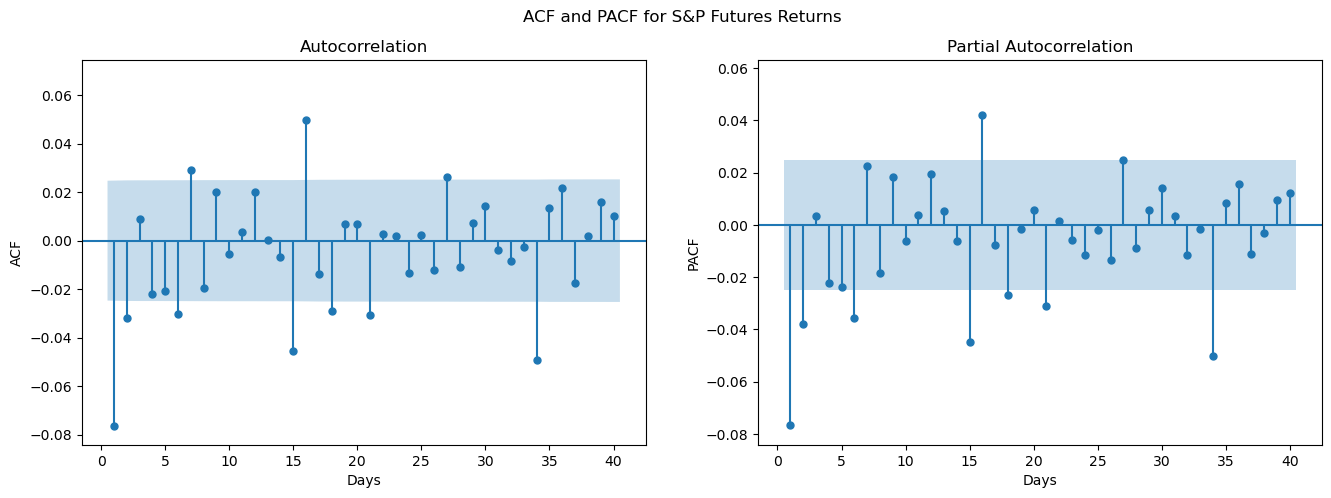

In [100]:
plot_acf_pacf_values(rtn, "ACF and PACF for S&P Futures Returns")

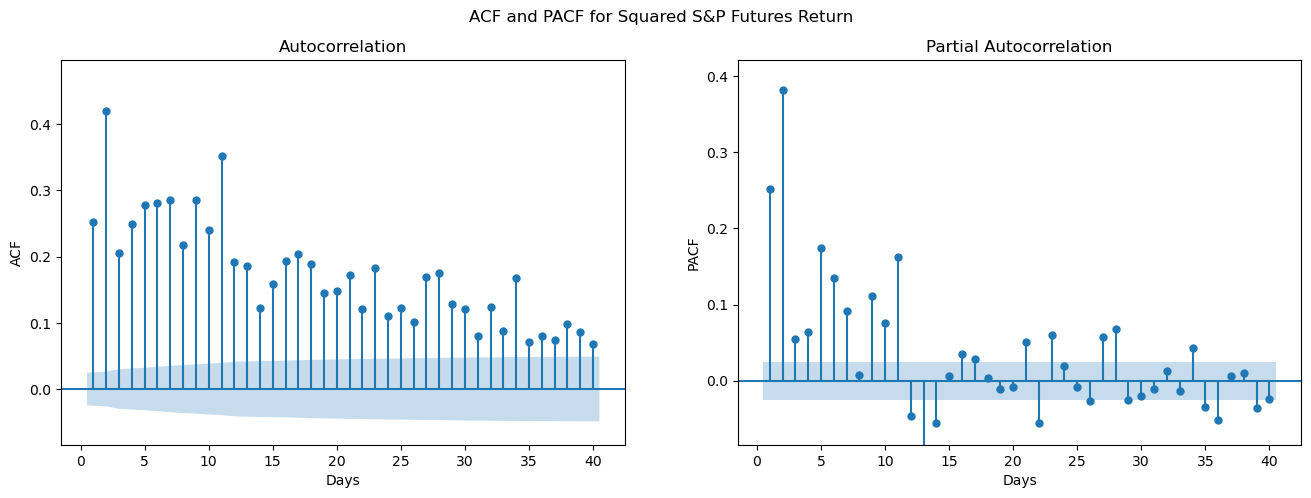

In [99]:
plot_acf_pacf_values(rtn ** 2, "ACF and PACF for Squared S&P Futures Return", 10)